In [2]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.cleaning import load_processed
from src.metrics import (add_core_metrics, add_growth_rate,
                         add_cumulative_net_intake, add_backlog_indicators)

df = add_backlog_indicators(
    add_cumulative_net_intake(add_growth_rate(add_core_metrics(load_processed()))))
rep = df[df["is_reported"]]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
print(rep[["backlog_flag_intake", "backlog_flag_care"]].sum())
print("longest intake streak:", rep["positive_intake_streak"].max())
print("longest care streak  :", rep["rising_care_streak"].max())

backlog_flag_intake    45
backlog_flag_care      63
dtype: Int64
longest intake streak: 12
longest care streak  : 14


In [4]:
print(pd.crosstab(rep["backlog_flag_intake"], rep["backlog_flag_care"]))
rep.groupby(rep.index.year)[["backlog_flag_intake", "backlog_flag_care"]].sum()

backlog_flag_care    False  True 
backlog_flag_intake              
False                  628     47
True                    29     16


,backlog_flag_intake,backlog_flag_care
date,,
2023,0,23
2024,38,18
2025,7,22


In [5]:
for n in [3, 5, 7, 10]:
    print(n, (rep["positive_intake_streak"] >= n).sum(),
             (rep["rising_care_streak"] >= n).sum())

3 96 172
5 45 63
7 27 38
10 6 13


In [6]:
def episodes(rep, streak_col, min_streak=5):
    cond = rep[streak_col] > 0
    run_id = (~cond).cumsum()
    rows = []
    for _, run in rep[cond].groupby(run_id[cond]):
        if len(run) >= min_streak:
            rows.append({
                "start": run.index[0].date(),
                "end": run.index[-1].date(),
                "reports": len(run),
                "calendar_days": (run.index[-1] - run.index[0]).days + 1,
                "net_intake_sum": int(run["net_daily_intake"].sum()),
            })
    return pd.DataFrame(rows)

print(episodes(rep, "positive_intake_streak"))
print(episodes(rep, "rising_care_streak"))

        start         end  reports  calendar_days  net_intake_sum
0  2024-04-21  2024-05-02       10             12            1028
1  2024-05-06  2024-05-15        8             10             252
2  2024-05-20  2024-06-03       10             15             595
3  2024-08-18  2024-09-05       12             19             720
4  2024-10-14  2024-10-23        8             10             336
5  2024-11-04  2024-11-14        8             11             198
6  2024-11-25  2024-12-08       10             14             670
7  2025-03-19  2025-03-31        9             13              51
8  2025-05-07  2025-05-14        6              8              30
         start         end  reports  calendar_days  net_intake_sum
0   2023-04-20  2023-05-04       11             15            -619
1   2023-07-31  2023-08-17       11             18           -1144
2   2023-11-20  2023-12-07       13             18           -2004
3   2024-04-15  2024-05-02       14             18            1100
4   2

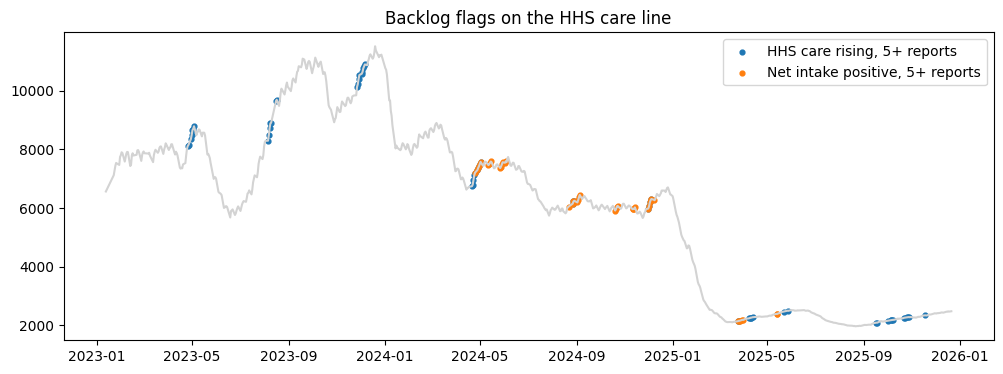

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(rep.index, rep["hhs_care"].astype(float), color="lightgray")
a = rep[rep["backlog_flag_intake"] == True]
b = rep[rep["backlog_flag_care"] == True]
ax.scatter(b.index, b["hhs_care"].astype(float), s=12, label="HHS care rising, 5+ reports")
ax.scatter(a.index, a["hhs_care"].astype(float), s=12, label="Net intake positive, 5+ reports")
ax.set_title("Backlog flags on the HHS care line")
ax.legend()